✅ Silhouette Score (K-Means por Referencia): 0.9469


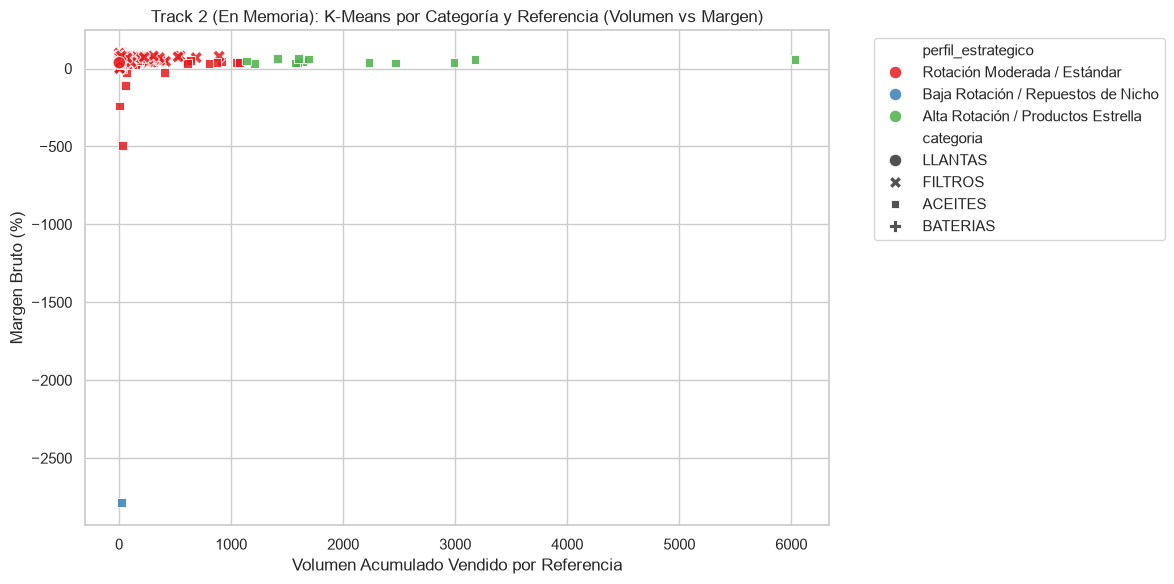


--- Muestra del DataFrame `df_segmentacion_ref` listo para usar en memoria ---


,codigo,descripcion,categoria,volumen_acumulado,MARGEN_BRUTO_PCT,perfil_estrategico
0,15,LLANTA GOLD PARTINER 12R 22.5 GP717A TRA,LLANTAS,8.00,36.97,Rotación Moderada / Estándar
1,46,LLANTA CONTINENTAL 235-55-20 CROSSCONTACT UHP,LLANTAS,2.00,36.97,Rotación Moderada / Estándar
2,48,LLANTA APTANY 175-70-14C 8 LONAS 95/93T RL106,LLANTAS,6.00,36.97,Rotación Moderada / Estándar
3,49,LLANTA MOTO 110-80-18 MR923,LLANTAS,3.00,36.97,Rotación Moderada / Estándar
4,75,LLANTA HANKOOK 245-75-16 RF12,LLANTAS,8.00,36.97,Rotación Moderada / Estándar
5,78,LLANTA MOTO 120-80-18,LLANTAS,20.00,36.97,Rotación Moderada / Estándar
6,91,LLANTA ROYAL BLACK 195-60-16 MILE,LLANTAS,2.00,36.97,Rotación Moderada / Estándar
7,106,FILTRO AIRE FA132,FILTROS,4.00,47.44,Rotación Moderada / Estándar
8,111,LLANTA HANKOOK 265-65-17 RF11,LLANTAS,8.00,36.97,Rotación Moderada / Estándar
9,189,LLANTA BRIDGESTONE 205-75R17.5 R294,LLANTAS,5.00,36.97,Rotación Moderada / Estándar


In [8]:
# ==============================================================================
# TRACK 2 (DIRECTO EN MEMORIA): K-MEANS A NIVEL DE CATEGORÍA Y REFERENCIA
# ==============================================================================

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 1. CARGAR DATOS DESDE LAS VARIABLES EXISTENTES O ARCHIVOS BASE
root = Path.cwd()
while not (root / 'data' / 'processed').is_dir():
    if root.parent == root:
        raise FileNotFoundError('No se encontró la carpeta data/processed del proyecto.')
    root = root.parent
processed_dir = root / 'data' / 'processed'

df_inv = pd.read_csv(processed_dir / 'INVENTARIO_PRODUCTOS_LIMPIO.csv')
df_ventas = pd.read_csv(processed_dir / 'ventas_limpia.csv')

df_inv['codigo'] = df_inv['codigo'].astype(str)
df_ventas['codigo'] = df_ventas['codigo'].astype(str)

# 2. FILTRAR ESTRICTAMENTE LAS 4 FAMILIAS DE INTERÉS
categorias_validas = {'LLANTAS', 'BATERIAS', 'ACEITES', 'FILTROS'}
df_inv = df_inv[df_inv['categoria'].isin(categorias_validas)].copy()
df_ventas = df_ventas[df_ventas['categoria'].isin(categorias_validas)].copy()

# 3. CONSTRUCCIÓN DE MÉTRICAS A NIVEL DE REFERENCIA (CÓDIGO)
volumen_ventas_ref = df_ventas.groupby(['codigo', 'categoria'])['cantidad'].sum().reset_index()
volumen_ventas_ref = volumen_ventas_ref.rename(columns={'cantidad': 'volumen_acumulado'})

# Limpieza de costos y precios
df_inv['costo_c(COP)'] = pd.to_numeric(df_inv['costo_c(COP)'], errors='coerce').fillna(0)
df_inv['precio_v(COP)'] = pd.to_numeric(df_inv['precio_v(COP)'], errors='coerce').replace(0, np.nan)
df_inv['MARGEN_BRUTO_PCT'] = ((df_inv['precio_v(COP)'] - df_inv['costo_c(COP)']) / df_inv['precio_v(COP)']) * 100

# Consolidar dataset de segmentación por referencia
df_segmentacion_ref = df_inv[['codigo', 'categoria', 'descripcion', 'MARGEN_BRUTO_PCT', 'stock']].merge(
    volumen_ventas_ref[['codigo', 'volumen_acumulado']], on='codigo', how='inner'
)

# Sanitización de nulos e infinitos
df_segmentacion_ref['volumen_acumulado'] = df_segmentacion_ref['volumen_acumulado'].fillna(0)
df_segmentacion_ref['stock'] = df_segmentacion_ref['stock'].fillna(0)
df_segmentacion_ref['MARGEN_BRUTO_PCT'] = df_segmentacion_ref['MARGEN_BRUTO_PCT'].fillna(0)
df_segmentacion_ref.replace([np.inf, -np.inf], np.nan, inplace=True)
df_segmentacion_ref = df_segmentacion_ref.dropna(subset=['volumen_acumulado', 'MARGEN_BRUTO_PCT']).reset_index(drop=True)

# 4. ESCALADO Y APLICACIÓN DE K-MEANS POR REFERENCIA
X_raw = df_segmentacion_ref[['volumen_acumulado', 'MARGEN_BRUTO_PCT']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Entrenamiento de K-Means (3 clústeres)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_segmentacion_ref['cluster_kmeans'] = kmeans.fit_predict(X_scaled)
sil_kmeans = silhouette_score(X_scaled, df_segmentacion_ref['cluster_kmeans'])

print(f"✅ Silhouette Score (K-Means por Referencia): {sil_kmeans:.4f}")

# 5. ETIQUETADO DE PERFILES ESTRATÉGICOS DE NEGOCIO
medias_volumen = df_segmentacion_ref.groupby('cluster_kmeans')['volumen_acumulado'].mean().sort_values()
cluster_ordenado = list(medias_volumen.index)

df_segmentacion_ref['perfil_estrategico'] = df_segmentacion_ref['cluster_kmeans'].map({
    cluster_ordenado[0]: 'Baja Rotación / Repuestos de Nicho',
    cluster_ordenado[1]: 'Rotación Moderada / Estándar',
    cluster_ordenado[2]: 'Alta Rotación / Productos Estrella'
})

# ==============================================================================
# 6. VISUALIZACIÓN DEL MODELO Y MUESTRA EN MEMORIA
# ==============================================================================
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_segmentacion_ref, 
    x='volumen_acumulado', 
    y='MARGEN_BRUTO_PCT', 
    hue='perfil_estrategico', 
    style='categoria',
    palette='Set1', 
    s=80, 
    alpha=0.85
)
plt.title('Track 2 (En Memoria): K-Means por Categoría y Referencia (Volumen vs Margen)')
plt.xlabel('Volumen Acumulado Vendido por Referencia')
plt.ylabel('Margen Bruto (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("\n--- Muestra del DataFrame `df_segmentacion_ref` listo para usar en memoria ---")
display(df_segmentacion_ref[['codigo', 'descripcion', 'categoria', 'volumen_acumulado', 'MARGEN_BRUTO_PCT', 'perfil_estrategico']].head(10))